# Code Similarity Analysis: VidyaVichar MERN Implementations
## Q1: 27 Team Implementations Analysis

This notebook performs comprehensive code similarity analysis across multiple MERN stack implementations.

**Author:** Student Submission  
**Date:** 2025-11-04

## Setup and Imports

In [1]:
# Standard library imports
import os
import json
import re
import ast
from pathlib import Path
from collections import defaultdict, Counter
import difflib

# Data processing
import pandas as pd
import numpy as np

# Similarity metrics
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from Levenshtein import distance as levenshtein_distance

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import networkx as nx

# Warning suppression
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


## Part A: Preprocessing & Data Understanding
### Step 1: Project Discovery and Organization

In [2]:
# Define project root (parent directory of Q1)
PROJECT_ROOT = Path('data/').resolve()
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

# Discover all project directories
def discover_projects(root_path):
    """Find all project directories in the root path."""
    projects = []
    for item in root_path.iterdir():
        if item.is_dir() and not item.name.startswith('.') and item.name != 'Q1':
            projects.append({
                'name': item.name,
                'path': item,
                'team_id': extract_team_id(item.name)
            })
    return sorted(projects, key=lambda x: x['name'])

def extract_team_id(folder_name):
    """Extract team ID from folder name."""
    # Look for patterns like 'team25', 'group5', 'Team33', etc.
    match = re.search(r'(team|group|Team|Group)[-_]?(\d+)', folder_name, re.IGNORECASE)
    if match:
        return f"Team_{match.group(2).zfill(2)}"
    # Use folder name as fallback
    return folder_name[:20]  # Truncate for display

projects = discover_projects(PROJECT_ROOT)
print(f"Found {len(projects)} projects:")
for i, proj in enumerate(projects, 1):
    print(f"{i:2d}. {proj['team_id']:20s} - {proj['name']}")

Found 17 projects:
 1. Team_27              - Group_27_SSD_MID_LAB
 2. Team_21              - SSD_MID_group_21
 3. SSD_MidSem           - SSD_MidSem
 4. VidhyaVichaar        - VidhyaVichaar
 5. VidhyaVichar         - VidhyaVichar
 6. VidyaVichar          - VidyaVichar
 7. VidyaVichar-Classroo - VidyaVichar-Classroom-Q-A-sticky-board
 8. VidyaVichar-T28      - VidyaVichar-T28
 9. VidyaVicharT10       - VidyaVicharT10
10. VidyaVicharT22       - VidyaVicharT22
11. VidyaVichar_SSD_M25_ - VidyaVichar_SSD_M25_G20
12. Team_33              - VidyaVichar_Team33
13. Team_05              - Vidya_Vichar_group5
14. vidya-vichaar        - vidya-vichaar
15. vidya-vichar         - vidya-vichar
16. vidya-vichar-iiith-s - vidya-vichar-iiith-ssd-26-sep-25-mid-hackathon
17. Team_25              - vidyavichara-team25


### Step 2: Code Preprocessing Functions

In [3]:
def remove_comments_js(code):
    """Remove JavaScript/JSX comments from code."""
    # Remove single-line comments
    code = re.sub(r'//.*?$', '', code, flags=re.MULTILINE)
    # Remove multi-line comments
    code = re.sub(r'/\*.*?\*/', '', code, flags=re.DOTALL)
    return code

def normalize_code(code):
    """Normalize code formatting."""
    # Remove extra whitespace
    code = re.sub(r'\s+', ' ', code)
    # Remove leading/trailing whitespace
    code = code.strip()
    return code

def is_minified(file_path):
    """Check if a file is minified."""
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            first_line = f.readline()
            # If first line is very long, likely minified
            if len(first_line) > 500:
                return True
    except:
        pass
    return False

def should_skip_file(file_path):
    """Determine if a file should be skipped."""
    skip_patterns = [
        'node_modules', '.git', 'dist', 'build', '.next',
        'coverage', '.env', 'package-lock.json', 'yarn.lock',
        '.min.js', '.min.css', '.bundle.js'
    ]
    path_str = str(file_path)
    return any(pattern in path_str for pattern in skip_patterns) or is_minified(file_path)

def read_file_safe(file_path):
    """Safely read file content."""
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            return f.read()
    except Exception as e:
        return ""

def preprocess_file(file_path):
    """Preprocess a single file."""
    content = read_file_safe(file_path)
    if not content:
        return ""
    
    ext = file_path.suffix.lower()
    if ext in ['.js', '.jsx', '.ts', '.tsx']:
        content = remove_comments_js(content)
    
    content = normalize_code(content)
    return content

print("✓ Preprocessing functions defined")

✓ Preprocessing functions defined


### Step 3: File Analysis and Statistics

In [4]:
def count_lines_of_code(file_path):
    """Count non-empty lines of code."""
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            return sum(1 for line in f if line.strip())
    except:
        return 0

def is_react_component(file_path):
    """Check if file is a React component."""
    if file_path.suffix not in ['.js', '.jsx', '.ts', '.tsx']:
        return False
    content = read_file_safe(file_path)
    # Check for React patterns
    patterns = [
        r'import.*React',
        r'from ["\']react["\']',
        r'export default.*(?:function|class|const)',
        r'<[A-Z][\w]*',  # JSX tags
    ]
    return any(re.search(pattern, content) for pattern in patterns)

def is_express_route(file_path):
    """Check if file contains Express routes."""
    if file_path.suffix != '.js':
        return False
    content = read_file_safe(file_path)
    patterns = [
        r'express\(\)',
        r'Router\(\)',
        r'\.get\(["\']',
        r'\.post\(["\']',
        r'\.put\(["\']',
        r'\.delete\(["\']',
    ]
    return any(re.search(pattern, content) for pattern in patterns)

def is_mongoose_model(file_path):
    """Check if file is a Mongoose model."""
    if file_path.suffix != '.js':
        return False
    content = read_file_safe(file_path)
    patterns = [
        r'mongoose\.model',
        r'mongoose\.Schema',
        r'new Schema\(',
        r'from ["\']mongoose["\']',
    ]
    return any(re.search(pattern, content) for pattern in patterns)

def analyze_project(project_info):
    """Analyze a single project and collect statistics."""
    path = project_info['path']
    stats = {
        'name': project_info['team_id'],
        'folder_name': project_info['name'],
        'total_files': 0,
        'total_folders': 0,
        'total_loc': 0,
        'js_files': 0,
        'jsx_files': 0,
        'json_files': 0,
        'css_files': 0,
        'react_components': 0,
        'express_routes': 0,
        'mongoose_models': 0,
    }
    
    # Walk through project directory
    for root, dirs, files in os.walk(path):
        # Skip excluded directories
        dirs[:] = [d for d in dirs if d not in ['node_modules', '.git', 'dist', 'build', '.next']]
        
        stats['total_folders'] += len(dirs)
        
        for file in files:
            file_path = Path(root) / file
            
            if should_skip_file(file_path):
                continue
            
            stats['total_files'] += 1
            stats['total_loc'] += count_lines_of_code(file_path)
            
            ext = file_path.suffix.lower()
            if ext == '.js':
                stats['js_files'] += 1
            elif ext == '.jsx':
                stats['jsx_files'] += 1
            elif ext == '.json':
                stats['json_files'] += 1
            elif ext == '.css':
                stats['css_files'] += 1
            
            # Identify component types
            if is_react_component(file_path):
                stats['react_components'] += 1
            if is_express_route(file_path):
                stats['express_routes'] += 1
            if is_mongoose_model(file_path):
                stats['mongoose_models'] += 1
    
    return stats

print("✓ Analysis functions defined")

✓ Analysis functions defined


In [5]:
# Analyze all projects
print("Analyzing projects... This may take a few minutes.\n")

project_stats = []
for i, project in enumerate(projects, 1):
    print(f"Analyzing {i}/{len(projects)}: {project['team_id']}")
    stats = analyze_project(project)
    project_stats.append(stats)

# Create DataFrame
df_stats = pd.DataFrame(project_stats)

# Display summary
print("\n" + "="*80)
print("PROJECT STATISTICS SUMMARY")
print("="*80)
print(df_stats.to_string(index=False))

# Save to CSV
csv_path = RESULTS_DIR / 'preprocessing_summary.csv'
df_stats.to_csv(csv_path, index=False)
print(f"\n✓ Statistics saved to {csv_path}")

Analyzing projects... This may take a few minutes.

Analyzing 1/17: Team_27
Analyzing 2/17: Team_21
Analyzing 3/17: SSD_MidSem
Analyzing 4/17: VidhyaVichaar
Analyzing 5/17: VidhyaVichar
Analyzing 6/17: VidyaVichar
Analyzing 7/17: VidyaVichar-Classroo
Analyzing 8/17: VidyaVichar-T28
Analyzing 9/17: VidyaVicharT10
Analyzing 10/17: VidyaVicharT22
Analyzing 11/17: VidyaVichar_SSD_M25_
Analyzing 12/17: Team_33
Analyzing 13/17: Team_05
Analyzing 14/17: vidya-vichaar
Analyzing 15/17: vidya-vichar
Analyzing 16/17: vidya-vichar-iiith-s
Analyzing 17/17: Team_25

PROJECT STATISTICS SUMMARY
                name                                    folder_name  total_files  total_folders  total_loc  js_files  jsx_files  json_files  css_files  react_components  express_routes  mongoose_models
             Team_27                           Group_27_SSD_MID_LAB           62             18       6075        39         10           2          1                11              17                3
          

In [6]:
# Display aggregate statistics
print("\nAGGREGATE STATISTICS:")
print("=" * 50)
print(f"Total Projects Analyzed: {len(df_stats)}")
print(f"Total Lines of Code: {df_stats['total_loc'].sum():,}")
print(f"Average LOC per Project: {df_stats['total_loc'].mean():.0f}")
print(f"Total React Components: {df_stats['react_components'].sum()}")
print(f"Total Express Routes: {df_stats['express_routes'].sum()}")
print(f"Total Mongoose Models: {df_stats['mongoose_models'].sum()}")
print("\nTop 5 Projects by LOC:")
print(df_stats.nlargest(5, 'total_loc')[['name', 'total_loc']])


AGGREGATE STATISTICS:
Total Projects Analyzed: 17
Total Lines of Code: 109,204
Average LOC per Project: 6424
Total React Components: 286
Total Express Routes: 95
Total Mongoose Models: 57

Top 5 Projects by LOC:
                    name  total_loc
16               Team_25      33309
8         VidyaVicharT10      13202
15  vidya-vichar-iiith-s      11026
9         VidyaVicharT22       7305
0                Team_27       6075


## Part B: Code Similarity Computation
### Level 1: Textual Similarity (TF-IDF + Cosine Similarity)

In [7]:
def extract_code_corpus(project_info):
    """Extract all relevant code from a project into a single corpus."""
    path = project_info['path']
    corpus = []
    
    target_extensions = {'.js', '.jsx', '.ts', '.tsx', '.json', '.css'}
    
    for root, dirs, files in os.walk(path):
        dirs[:] = [d for d in dirs if d not in ['node_modules', '.git', 'dist', 'build']]
        
        for file in files:
            file_path = Path(root) / file
            
            if file_path.suffix.lower() in target_extensions and not should_skip_file(file_path):
                content = preprocess_file(file_path)
                if content:
                    corpus.append(content)
    
    # Join all files into single document
    return ' '.join(corpus)

# Extract corpus for all projects
print("Extracting code corpus from all projects...\n")
project_corpora = []
project_names = []

for i, project in enumerate(projects, 1):
    print(f"Extracting {i}/{len(projects)}: {project['team_id']}")
    corpus = extract_code_corpus(project)
    project_corpora.append(corpus)
    project_names.append(project['team_id'])

print(f"\n✓ Extracted corpus from {len(project_corpora)} projects")

Extracting code corpus from all projects...

Extracting 1/17: Team_27
Extracting 2/17: Team_21
Extracting 3/17: SSD_MidSem
Extracting 4/17: VidhyaVichaar
Extracting 5/17: VidhyaVichar
Extracting 6/17: VidyaVichar
Extracting 7/17: VidyaVichar-Classroo
Extracting 8/17: VidyaVichar-T28
Extracting 9/17: VidyaVicharT10
Extracting 10/17: VidyaVicharT22
Extracting 11/17: VidyaVichar_SSD_M25_
Extracting 12/17: Team_33
Extracting 13/17: Team_05
Extracting 14/17: vidya-vichaar
Extracting 15/17: vidya-vichar
Extracting 16/17: vidya-vichar-iiith-s
Extracting 17/17: Team_25

✓ Extracted corpus from 17 projects


In [8]:
# Compute TF-IDF vectors
print("Computing TF-IDF vectors...")

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 3),
    min_df=1,
    max_df=0.8,
    token_pattern=r'\b\w+\b'
)

tfidf_matrix = vectorizer.fit_transform(project_corpora)
print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")

# Compute cosine similarity
textual_similarity = cosine_similarity(tfidf_matrix)

# Create DataFrame
df_textual = pd.DataFrame(
    textual_similarity,
    index=project_names,
    columns=project_names
)

print("\n✓ Textual similarity matrix computed")
print(f"\nSimilarity range: [{textual_similarity.min():.3f}, {textual_similarity.max():.3f}]")

# Save matrix
df_textual.to_csv(RESULTS_DIR / 'textual_similarity_matrix.csv')
print(f"✓ Saved to {RESULTS_DIR / 'textual_similarity_matrix.csv'}")

Computing TF-IDF vectors...
TF-IDF matrix shape: (17, 5000)

✓ Textual similarity matrix computed

Similarity range: [0.000, 1.000]
✓ Saved to results/textual_similarity_matrix.csv


### Level 2: Structural Similarity (AST-based & File Structure)

In [9]:
def extract_file_structure(project_info):
    """Extract file/folder structure as a feature vector."""
    path = project_info['path']
    structure_features = {
        'depth': 0,
        'folders': [],
        'file_types': Counter(),
        'folder_names': Counter(),
    }
    
    for root, dirs, files in os.walk(path):
        dirs[:] = [d for d in dirs if d not in ['node_modules', '.git', 'dist', 'build']]
        
        depth = str(root).count(os.sep) - str(path).count(os.sep)
        structure_features['depth'] = max(structure_features['depth'], depth)
        
        for dir_name in dirs:
            structure_features['folder_names'][dir_name.lower()] += 1
        
        for file in files:
            ext = Path(file).suffix.lower()
            if ext:
                structure_features['file_types'][ext] += 1
    
    return structure_features

def compute_structural_similarity(feat1, feat2):
    """Compute similarity between two structural feature sets."""
    # Depth similarity (normalized)
    max_depth = max(feat1['depth'], feat2['depth'], 1)
    depth_sim = 1 - abs(feat1['depth'] - feat2['depth']) / max_depth
    
    # Folder name similarity (Jaccard)
    folders1 = set(feat1['folder_names'].keys())
    folders2 = set(feat2['folder_names'].keys())
    if folders1 or folders2:
        folder_sim = len(folders1 & folders2) / len(folders1 | folders2)
    else:
        folder_sim = 0
    
    # File type similarity (cosine of counts)
    all_types = set(feat1['file_types'].keys()) | set(feat2['file_types'].keys())
    vec1 = np.array([feat1['file_types'].get(t, 0) for t in all_types])
    vec2 = np.array([feat2['file_types'].get(t, 0) for t in all_types])
    
    if np.linalg.norm(vec1) > 0 and np.linalg.norm(vec2) > 0:
        type_sim = np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))
    else:
        type_sim = 0
    
    # Weighted average
    return 0.2 * depth_sim + 0.4 * folder_sim + 0.4 * type_sim

print("Computing structural similarity...\n")

# Extract features
structural_features = []
for i, project in enumerate(projects, 1):
    print(f"Analyzing structure {i}/{len(projects)}: {project['team_id']}")
    features = extract_file_structure(project)
    structural_features.append(features)

# Compute pairwise similarity
n = len(projects)
structural_similarity = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        structural_similarity[i, j] = compute_structural_similarity(
            structural_features[i],
            structural_features[j]
        )

# Create DataFrame
df_structural = pd.DataFrame(
    structural_similarity,
    index=project_names,
    columns=project_names
)

print("\n✓ Structural similarity matrix computed")
print(f"Similarity range: [{structural_similarity.min():.3f}, {structural_similarity.max():.3f}]")

# Save matrix
df_structural.to_csv(RESULTS_DIR / 'structural_similarity_matrix.csv')
print(f"✓ Saved to {RESULTS_DIR / 'structural_similarity_matrix.csv'}")

Computing structural similarity...

Analyzing structure 1/17: Team_27
Analyzing structure 2/17: Team_21
Analyzing structure 3/17: SSD_MidSem
Analyzing structure 4/17: VidhyaVichaar
Analyzing structure 5/17: VidhyaVichar
Analyzing structure 6/17: VidyaVichar
Analyzing structure 7/17: VidyaVichar-Classroo
Analyzing structure 8/17: VidyaVichar-T28
Analyzing structure 9/17: VidyaVicharT10
Analyzing structure 10/17: VidyaVicharT22
Analyzing structure 11/17: VidyaVichar_SSD_M25_
Analyzing structure 12/17: Team_33
Analyzing structure 13/17: Team_05
Analyzing structure 14/17: vidya-vichaar
Analyzing structure 15/17: vidya-vichar
Analyzing structure 16/17: vidya-vichar-iiith-s
Analyzing structure 17/17: Team_25

✓ Structural similarity matrix computed
Similarity range: [0.008, 1.000]
✓ Saved to results/structural_similarity_matrix.csv


### Level 3: Semantic Similarity (Code Embeddings)

In [10]:
# For semantic similarity, we'll use a combination of:
# 1. Function/component name similarity
# 2. API endpoint pattern similarity
# 3. Import/dependency similarity

def extract_semantic_features(project_info):
    """Extract semantic features from project."""
    path = project_info['path']
    features = {
        'function_names': set(),
        'component_names': set(),
        'api_endpoints': set(),
        'imports': set(),
        'dependencies': set(),
    }
    
    for root, dirs, files in os.walk(path):
        dirs[:] = [d for d in dirs if d not in ['node_modules', '.git', 'dist', 'build']]
        
        for file in files:
            file_path = Path(root) / file
            
            if file_path.suffix in ['.js', '.jsx', '.ts', '.tsx'] and not should_skip_file(file_path):
                content = read_file_safe(file_path)
                
                # Extract function names
                func_matches = re.findall(r'function\s+(\w+)\s*\(', content)
                features['function_names'].update(func_matches)
                
                # Extract const function names
                const_matches = re.findall(r'const\s+(\w+)\s*=\s*(?:async\s*)?\([^)]*\)\s*=>', content)
                features['function_names'].update(const_matches)
                
                # Extract component names (capitalized)
                comp_matches = re.findall(r'(?:function|const)\s+([A-Z]\w+)', content)
                features['component_names'].update(comp_matches)
                
                # Extract API endpoints
                api_matches = re.findall(r'["\']/(api/)?([\w/-]+)["\']', content)
                features['api_endpoints'].update([m[1] for m in api_matches if m[1]])
                
                # Extract imports
                import_matches = re.findall(r'from\s+["\']([^"\'\.][^"\']*)["\']', content)
                features['imports'].update(import_matches)
            
            # Extract dependencies from package.json
            if file == 'package.json':
                try:
                    pkg_data = json.loads(read_file_safe(file_path))
                    if 'dependencies' in pkg_data:
                        features['dependencies'].update(pkg_data['dependencies'].keys())
                    if 'devDependencies' in pkg_data:
                        features['dependencies'].update(pkg_data['devDependencies'].keys())
                except:
                    pass
    
    return features

def compute_semantic_similarity(feat1, feat2):
    """Compute semantic similarity between two feature sets."""
    similarities = []
    
    # Function name similarity
    if feat1['function_names'] or feat2['function_names']:
        func_sim = len(feat1['function_names'] & feat2['function_names']) / \
                   len(feat1['function_names'] | feat2['function_names'])
        similarities.append(func_sim)
    
    # Component name similarity
    if feat1['component_names'] or feat2['component_names']:
        comp_sim = len(feat1['component_names'] & feat2['component_names']) / \
                   len(feat1['component_names'] | feat2['component_names'])
        similarities.append(comp_sim)
    
    # API endpoint similarity
    if feat1['api_endpoints'] or feat2['api_endpoints']:
        api_sim = len(feat1['api_endpoints'] & feat2['api_endpoints']) / \
                  len(feat1['api_endpoints'] | feat2['api_endpoints'])
        similarities.append(api_sim)
    
    # Dependency similarity
    if feat1['dependencies'] or feat2['dependencies']:
        dep_sim = len(feat1['dependencies'] & feat2['dependencies']) / \
                  len(feat1['dependencies'] | feat2['dependencies'])
        similarities.append(dep_sim)
    
    return np.mean(similarities) if similarities else 0.0

print("Computing semantic similarity...\n")

# Extract features
semantic_features = []
for i, project in enumerate(projects, 1):
    print(f"Extracting semantic features {i}/{len(projects)}: {project['team_id']}")
    features = extract_semantic_features(project)
    semantic_features.append(features)

# Compute pairwise similarity
n = len(projects)
semantic_similarity = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        semantic_similarity[i, j] = compute_semantic_similarity(
            semantic_features[i],
            semantic_features[j]
        )

# Create DataFrame
df_semantic = pd.DataFrame(
    semantic_similarity,
    index=project_names,
    columns=project_names
)

print("\n✓ Semantic similarity matrix computed")
print(f"Similarity range: [{semantic_similarity.min():.3f}, {semantic_similarity.max():.3f}]")

# Save matrix
df_semantic.to_csv(RESULTS_DIR / 'semantic_similarity_matrix.csv')
print(f"✓ Saved to {RESULTS_DIR / 'semantic_similarity_matrix.csv'}")

Computing semantic similarity...

Extracting semantic features 1/17: Team_27
Extracting semantic features 2/17: Team_21
Extracting semantic features 3/17: SSD_MidSem
Extracting semantic features 4/17: VidhyaVichaar
Extracting semantic features 5/17: VidhyaVichar
Extracting semantic features 6/17: VidyaVichar
Extracting semantic features 7/17: VidyaVichar-Classroo
Extracting semantic features 8/17: VidyaVichar-T28
Extracting semantic features 9/17: VidyaVicharT10
Extracting semantic features 10/17: VidyaVicharT22
Extracting semantic features 11/17: VidyaVichar_SSD_M25_
Extracting semantic features 12/17: Team_33
Extracting semantic features 13/17: Team_05
Extracting semantic features 14/17: vidya-vichaar
Extracting semantic features 15/17: vidya-vichar
Extracting semantic features 16/17: vidya-vichar-iiith-s
Extracting semantic features 17/17: Team_25

✓ Semantic similarity matrix computed
Similarity range: [0.000, 1.000]
✓ Saved to results/semantic_similarity_matrix.csv


### Combined Similarity Score

In [11]:
# Compute weighted average of all three similarity measures
weights = {'textual': 0.4, 'structural': 0.3, 'semantic': 0.3}

combined_similarity = (
    weights['textual'] * textual_similarity +
    weights['structural'] * structural_similarity +
    weights['semantic'] * semantic_similarity
)

df_combined = pd.DataFrame(
    combined_similarity,
    index=project_names,
    columns=project_names
)

# Save combined matrix
df_combined.to_csv(RESULTS_DIR / 'combined_similarity_matrix.csv')
print(f"✓ Combined similarity matrix saved")
print(f"Weights used: {weights}")

✓ Combined similarity matrix saved
Weights used: {'textual': 0.4, 'structural': 0.3, 'semantic': 0.3}


### Similarity Analysis and Interpretation

In [12]:
# Find most and least similar project pairs
def find_extreme_pairs(similarity_matrix, names, top_n=5):
    """Find most and least similar project pairs."""
    n = len(names)
    pairs = []
    
    for i in range(n):
        for j in range(i+1, n):
            pairs.append((names[i], names[j], similarity_matrix[i, j]))
    
    pairs.sort(key=lambda x: x[2], reverse=True)
    return pairs[:top_n], pairs[-top_n:]

most_similar, least_similar = find_extreme_pairs(combined_similarity, project_names)

print("\n" + "="*80)
print("MOST SIMILAR PROJECT PAIRS (Combined Score)")
print("="*80)
for i, (p1, p2, score) in enumerate(most_similar, 1):
    print(f"{i}. {p1:20s} <-> {p2:20s} : {score:.4f}")

print("\n" + "="*80)
print("LEAST SIMILAR PROJECT PAIRS (Combined Score)")
print("="*80)
for i, (p1, p2, score) in enumerate(least_similar, 1):
    print(f"{i}. {p1:20s} <-> {p2:20s} : {score:.4f}")

# Average similarity by project
avg_similarity = combined_similarity.copy()
np.fill_diagonal(avg_similarity, 0)  # Exclude self-similarity
avg_scores = avg_similarity.mean(axis=1)

print("\n" + "="*80)
print("AVERAGE SIMILARITY TO OTHER PROJECTS")
print("="*80)
for i, (name, score) in enumerate(sorted(zip(project_names, avg_scores), key=lambda x: x[1], reverse=True), 1):
    print(f"{i:2d}. {name:30s} : {score:.4f}")


MOST SIMILAR PROJECT PAIRS (Combined Score)
1. VidyaVichar-Classroo <-> VidyaVichar-T28      : 0.5136
2. VidyaVichar-T28      <-> Team_33              : 0.5063
3. VidyaVichar-T28      <-> vidya-vichaar        : 0.4887
4. VidyaVichar-Classroo <-> Team_33              : 0.4756
5. VidyaVichar-Classroo <-> vidya-vichaar        : 0.4613

LEAST SIMILAR PROJECT PAIRS (Combined Score)
1. vidya-vichar         <-> Team_25              : 0.0044
2. VidyaVichar-T28      <-> vidya-vichar         : 0.0039
3. Team_05              <-> vidya-vichar         : 0.0036
4. VidyaVicharT22       <-> vidya-vichar         : 0.0027
5. VidyaVicharT10       <-> vidya-vichar         : 0.0024

AVERAGE SIMILARITY TO OTHER PROJECTS
 1. VidyaVichar-T28                : 0.3058
 2. VidyaVichar-Classroo           : 0.2952
 3. Team_33                        : 0.2910
 4. SSD_MidSem                     : 0.2910
 5. vidya-vichaar                  : 0.2837
 6. VidyaVichar                    : 0.2780
 7. Team_21                

## Part C: Visualization & Reporting
### Visualization 1: Similarity Heatmaps

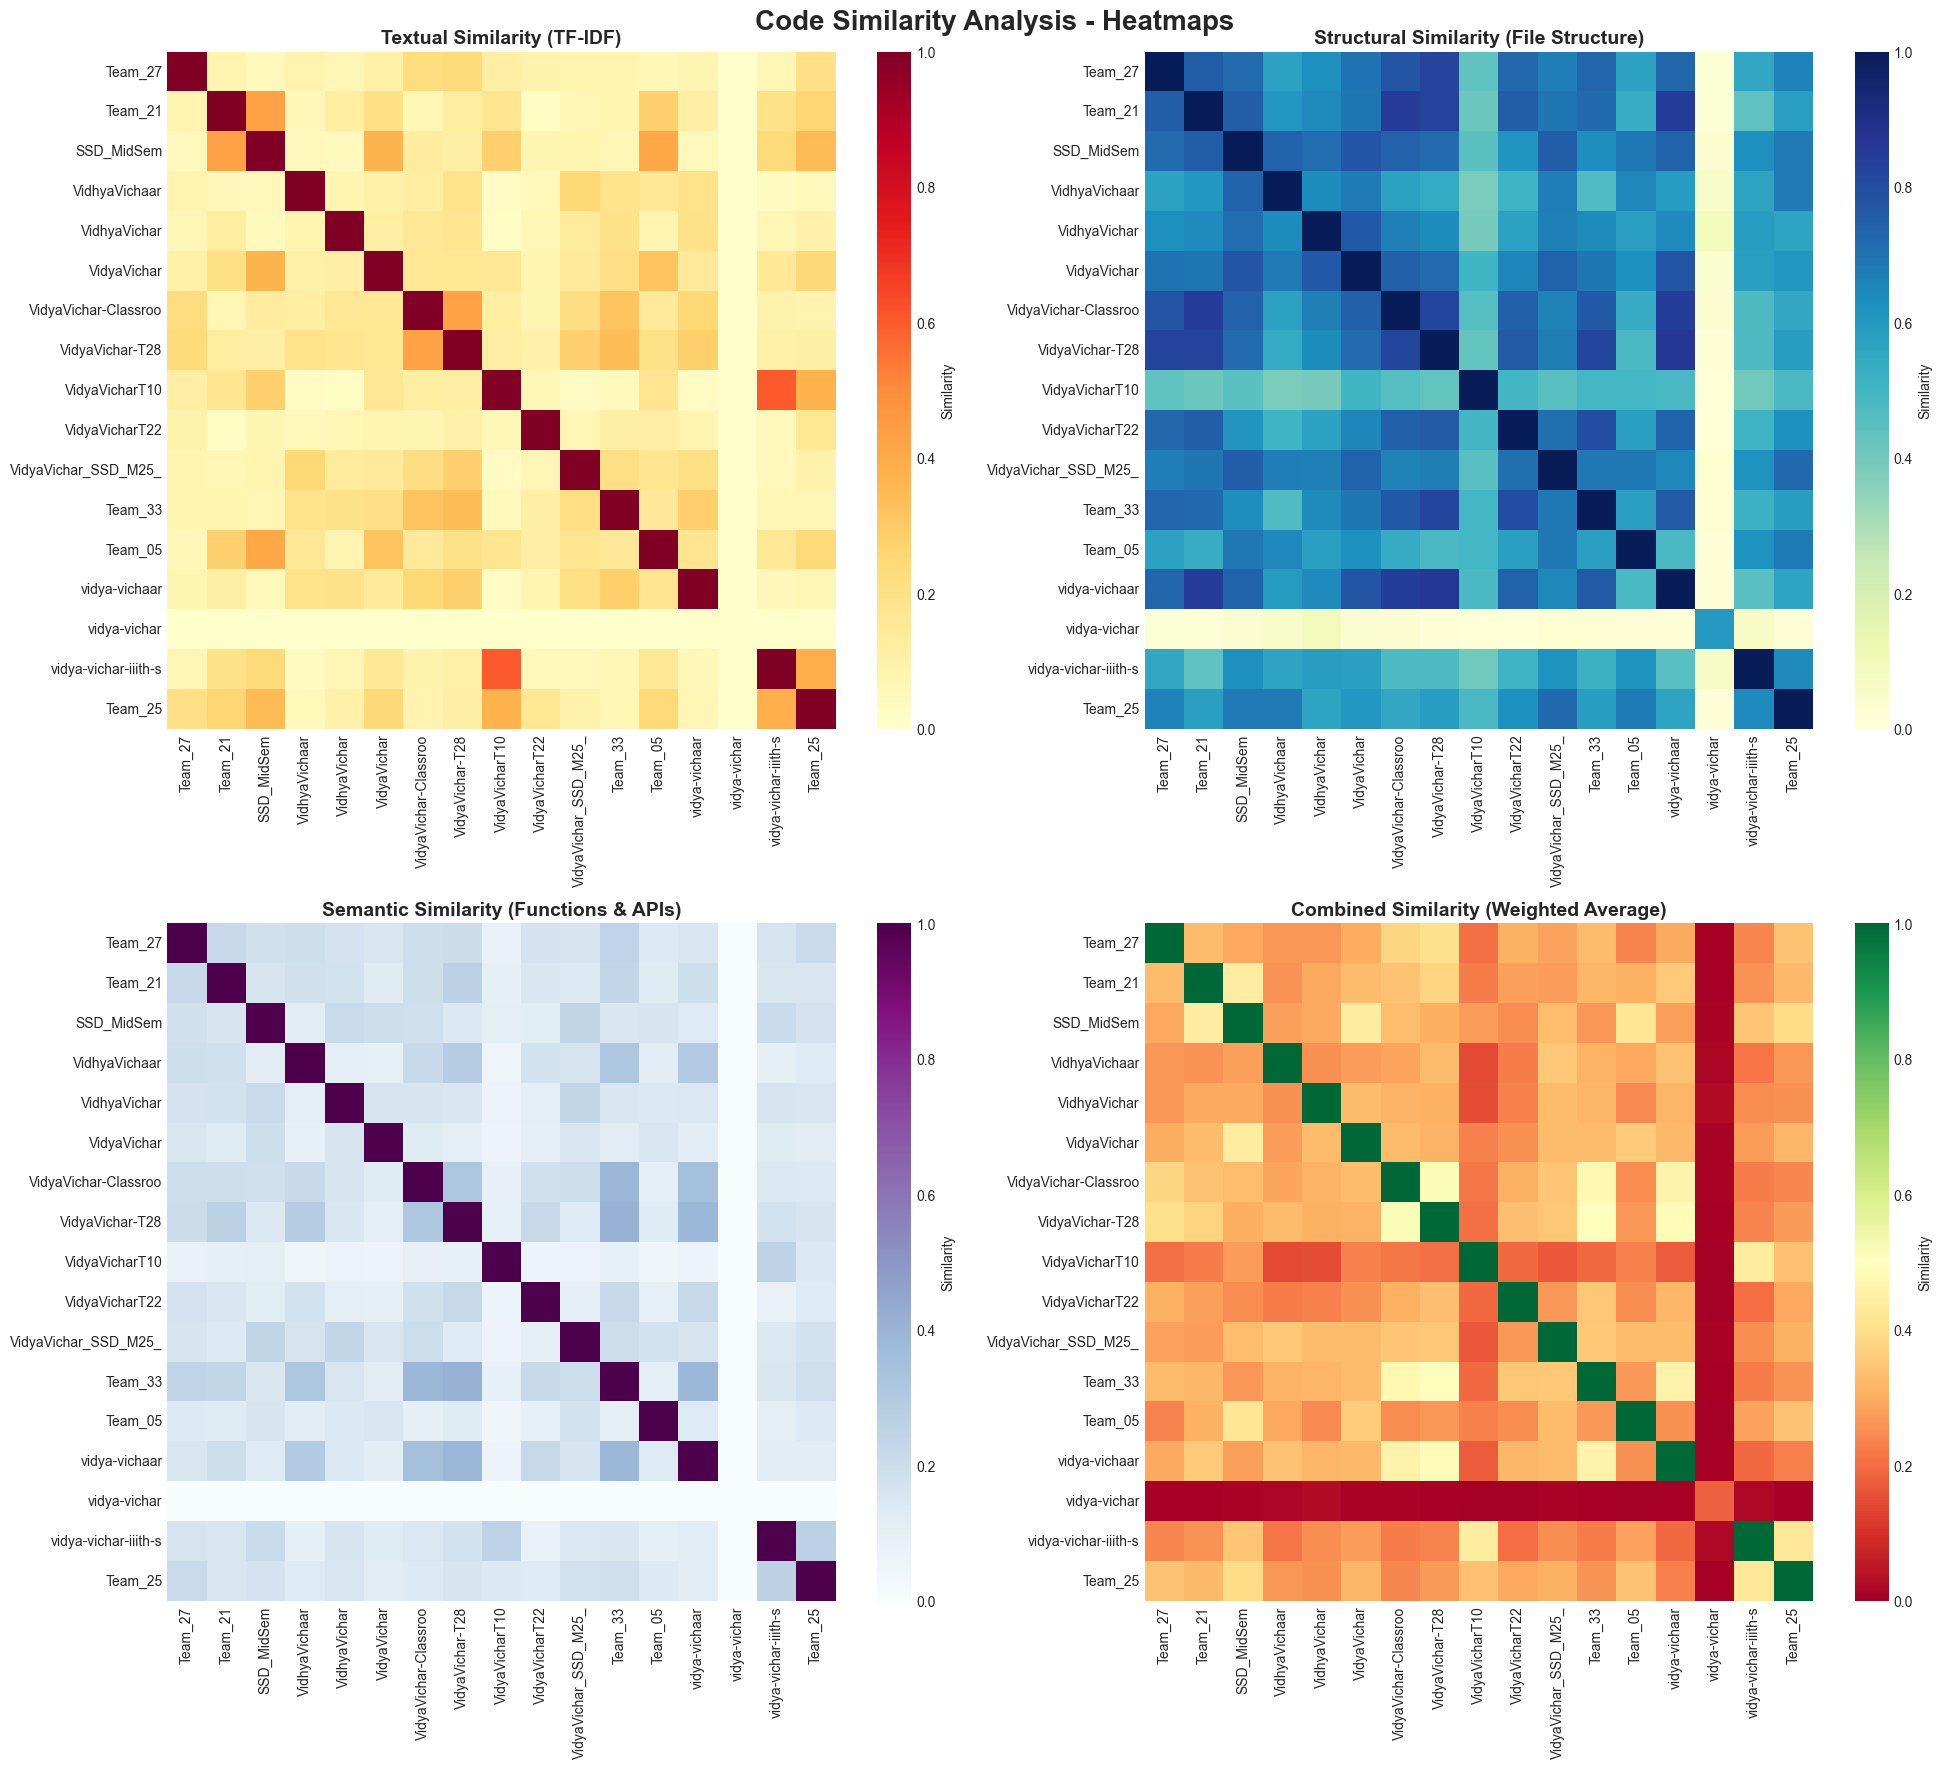

✓ Heatmaps saved to results/similarity_heatmaps.png


In [13]:
# Create comprehensive heatmap visualization
fig, axes = plt.subplots(2, 2, figsize=(20, 18))
fig.suptitle('Code Similarity Analysis - Heatmaps', fontsize=20, fontweight='bold')

# Textual similarity
sns.heatmap(df_textual, annot=False, cmap='YlOrRd', ax=axes[0, 0], 
            cbar_kws={'label': 'Similarity'}, vmin=0, vmax=1)
axes[0, 0].set_title('Textual Similarity (TF-IDF)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('')

# Structural similarity
sns.heatmap(df_structural, annot=False, cmap='YlGnBu', ax=axes[0, 1],
            cbar_kws={'label': 'Similarity'}, vmin=0, vmax=1)
axes[0, 1].set_title('Structural Similarity (File Structure)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('')

# Semantic similarity
sns.heatmap(df_semantic, annot=False, cmap='BuPu', ax=axes[1, 0],
            cbar_kws={'label': 'Similarity'}, vmin=0, vmax=1)
axes[1, 0].set_title('Semantic Similarity (Functions & APIs)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('')

# Combined similarity
sns.heatmap(df_combined, annot=False, cmap='RdYlGn', ax=axes[1, 1],
            cbar_kws={'label': 'Similarity'}, vmin=0, vmax=1)
axes[1, 1].set_title('Combined Similarity (Weighted Average)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'similarity_heatmaps.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Heatmaps saved to {RESULTS_DIR / 'similarity_heatmaps.png'}")

### Visualization 2: Network Graph of Project Clusters

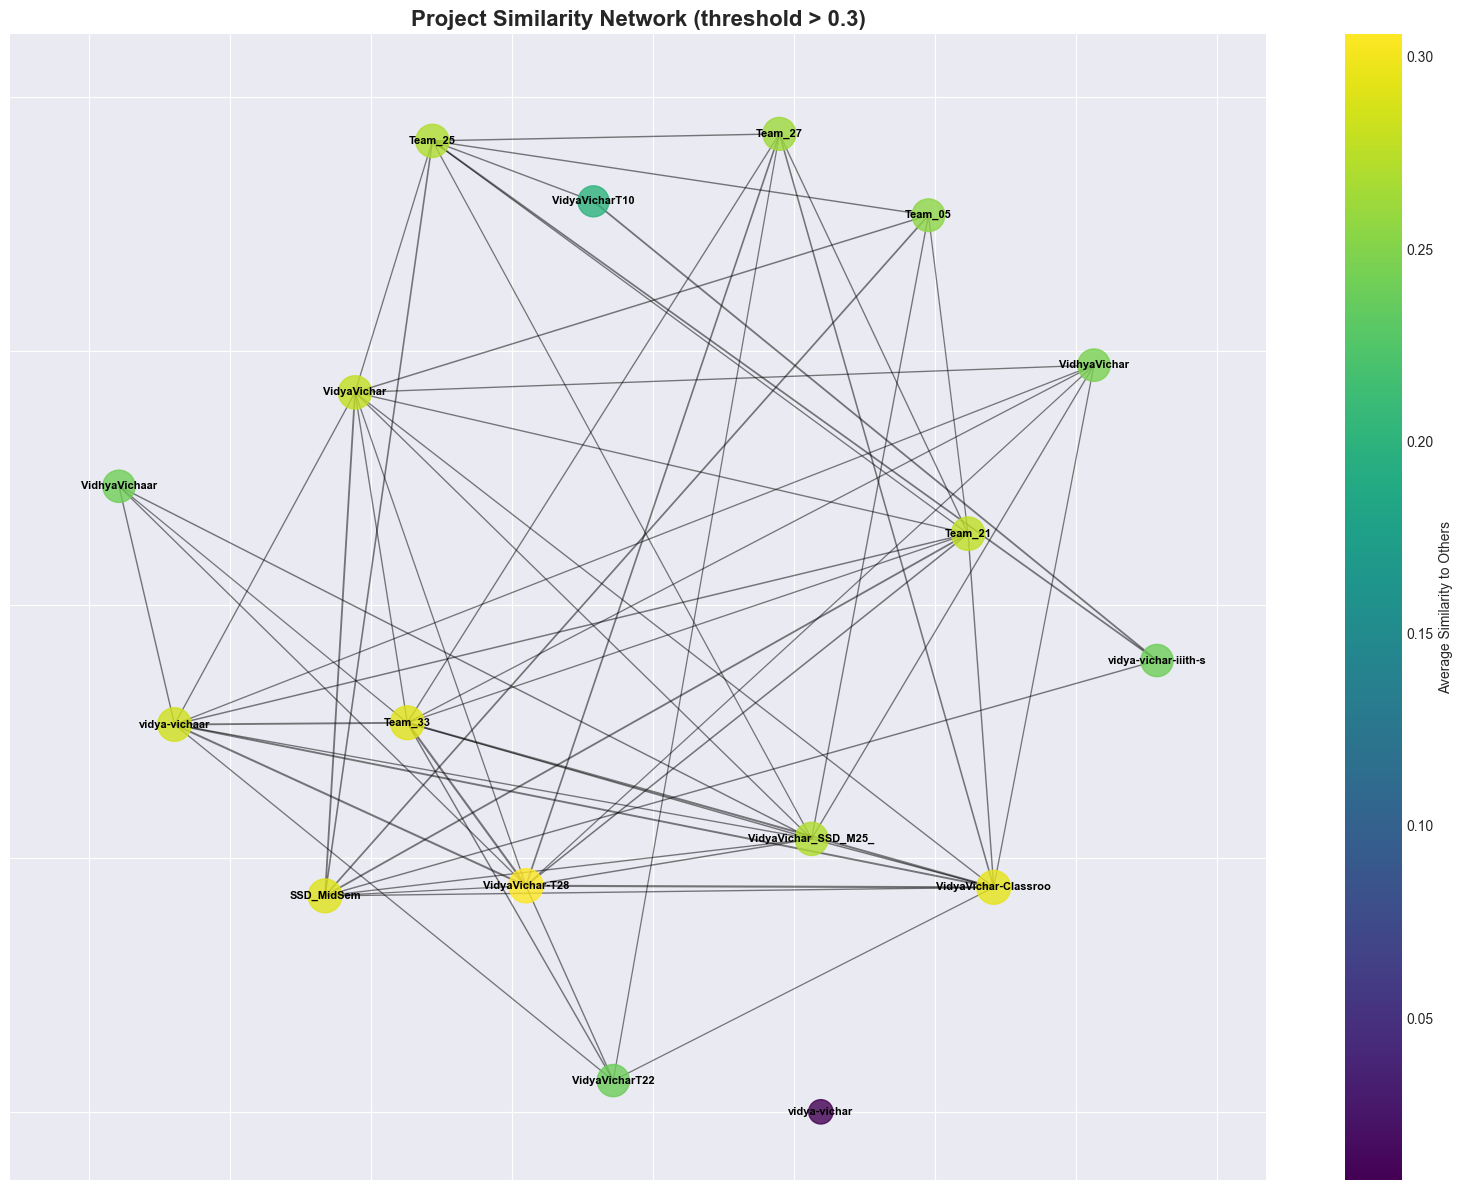

✓ Network graph saved to results/similarity_network.png

Network statistics:
  Nodes: 17
  Edges: 58
  Average degree: 6.82


In [14]:
# Create network graph based on similarity
threshold = 0.3  # Only show edges with similarity > threshold

G = nx.Graph()

# Add nodes
for name in project_names:
    G.add_node(name)

# Add edges for similar projects
n = len(project_names)
for i in range(n):
    for j in range(i+1, n):
        similarity = combined_similarity[i, j]
        if similarity > threshold:
            G.add_edge(project_names[i], project_names[j], weight=similarity)

# Compute layout
pos = nx.spring_layout(G, k=2, iterations=50, seed=42)

# Draw network
plt.figure(figsize=(16, 12))
plt.title(f'Project Similarity Network (threshold > {threshold})', fontsize=16, fontweight='bold')

# Draw edges with varying width based on similarity
edges = G.edges()
weights = [G[u][v]['weight'] for u, v in edges]
nx.draw_networkx_edges(G, pos, width=[w*3 for w in weights], alpha=0.5)

# Draw nodes
node_sizes = [300 + 1000 * avg_scores[i] for i in range(len(project_names))]
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=avg_scores, 
                       cmap='viridis', alpha=0.8)

# Draw labels
nx.draw_networkx_labels(G, pos, font_size=8, font_weight='bold')

sm = plt.cm.ScalarMappable(cmap='viridis',
                             norm=plt.Normalize(vmin=min(avg_scores), vmax=max(avg_scores)))
plt.colorbar(sm, ax=plt.gca(), label='Average Similarity to Others')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'similarity_network.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Network graph saved to {RESULTS_DIR / 'similarity_network.png'}")
print(f"\nNetwork statistics:")
print(f"  Nodes: {G.number_of_nodes()}")
print(f"  Edges: {G.number_of_edges()}")
print(f"  Average degree: {sum(dict(G.degree()).values()) / G.number_of_nodes():.2f}")

### Visualization 3: Comparative Bar Charts

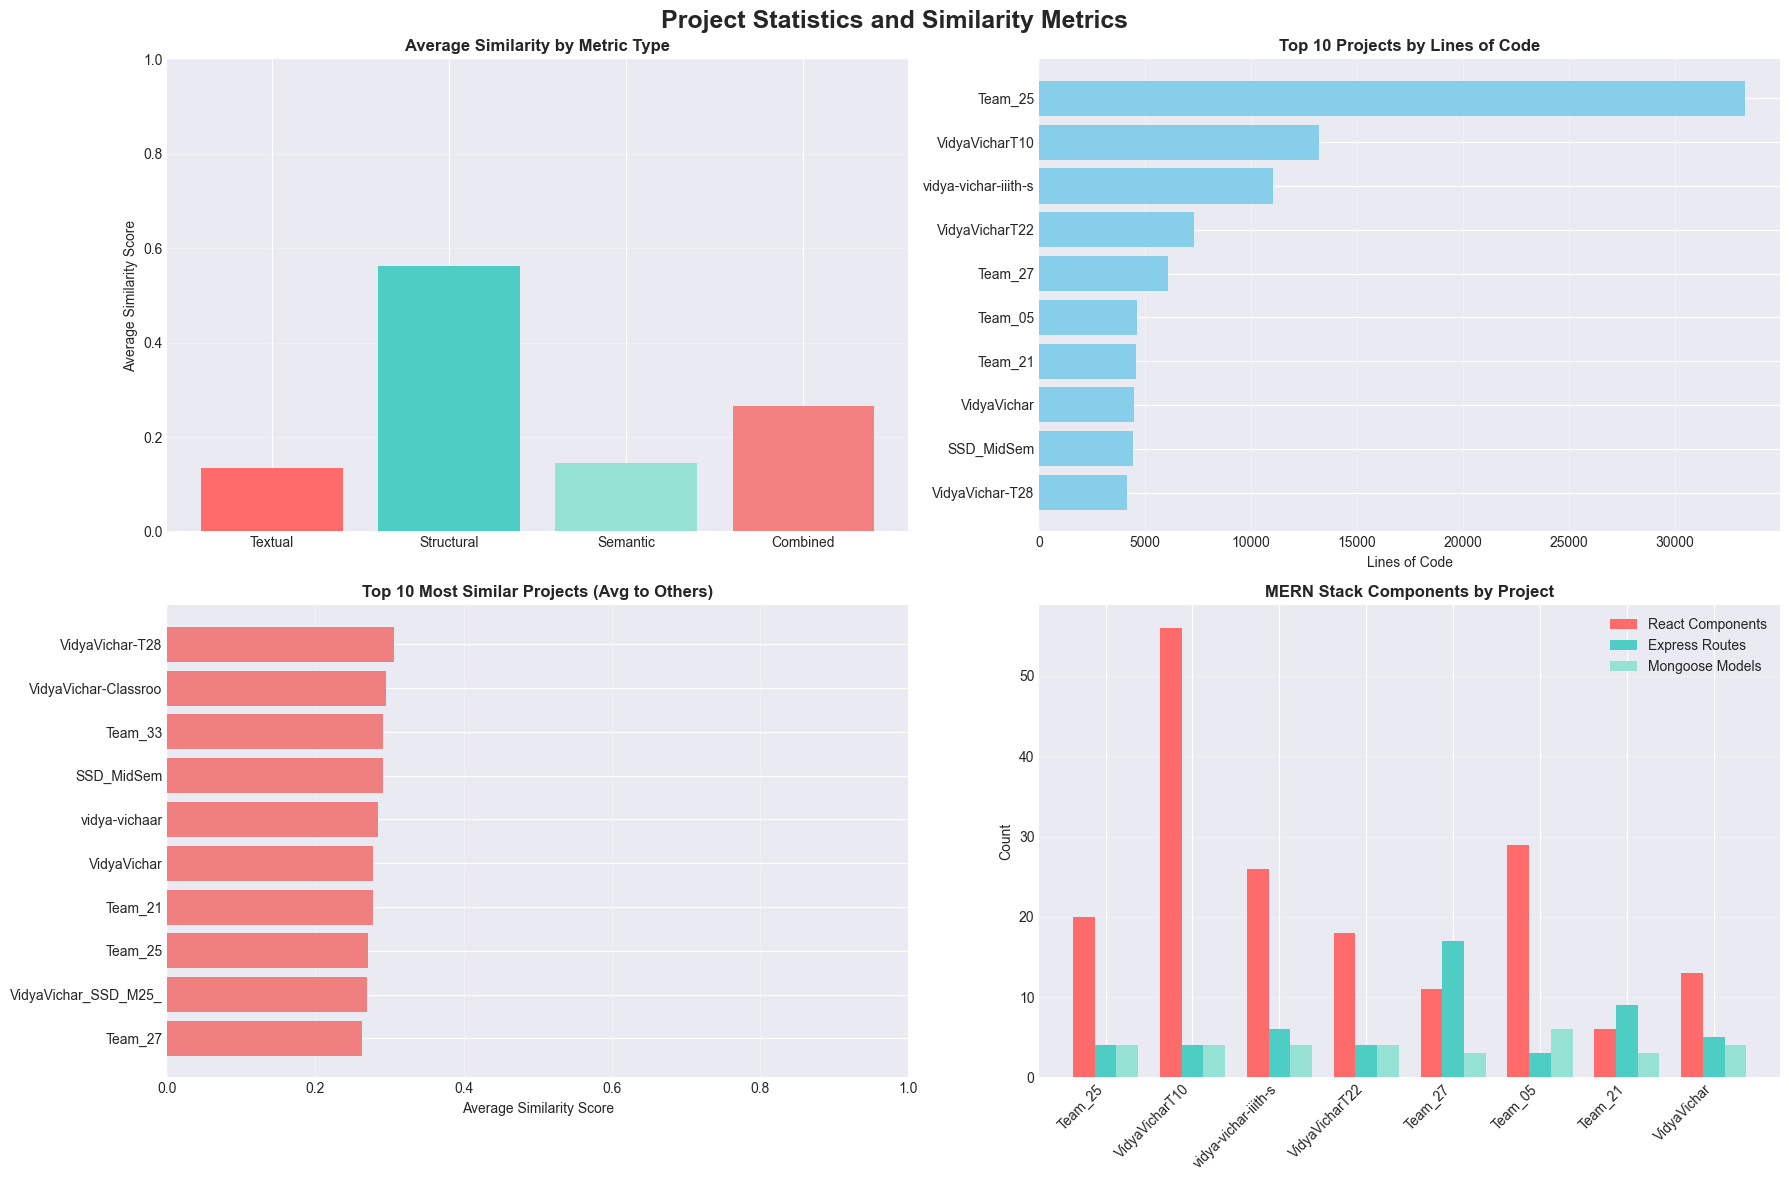

✓ Bar charts saved to results/comparative_charts.png


In [15]:
# Create comprehensive bar chart visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Project Statistics and Similarity Metrics', fontsize=18, fontweight='bold')

# Average similarity by metric
metrics_data = {
    'Textual': textual_similarity[np.triu_indices(n, k=1)].mean(),
    'Structural': structural_similarity[np.triu_indices(n, k=1)].mean(),
    'Semantic': semantic_similarity[np.triu_indices(n, k=1)].mean(),
    'Combined': combined_similarity[np.triu_indices(n, k=1)].mean(),
}
axes[0, 0].bar(metrics_data.keys(), metrics_data.values(), color=['#FF6B6B', '#4ECDC4', '#95E1D3', '#F38181'])
axes[0, 0].set_title('Average Similarity by Metric Type', fontweight='bold')
axes[0, 0].set_ylabel('Average Similarity Score')
axes[0, 0].set_ylim(0, 1)
axes[0, 0].grid(axis='y', alpha=0.3)

# Top 10 projects by LOC
top_loc = df_stats.nlargest(10, 'total_loc')[['name', 'total_loc']].sort_values('total_loc')
axes[0, 1].barh(range(len(top_loc)), top_loc['total_loc'], color='skyblue')
axes[0, 1].set_yticks(range(len(top_loc)))
axes[0, 1].set_yticklabels(top_loc['name'])
axes[0, 1].set_title('Top 10 Projects by Lines of Code', fontweight='bold')
axes[0, 1].set_xlabel('Lines of Code')
axes[0, 1].grid(axis='x', alpha=0.3)

# Average similarity to other projects (top 10)
top_avg_sim = pd.DataFrame({'name': project_names, 'avg_sim': avg_scores}).nlargest(10, 'avg_sim').sort_values('avg_sim')
axes[1, 0].barh(range(len(top_avg_sim)), top_avg_sim['avg_sim'], color='lightcoral')
axes[1, 0].set_yticks(range(len(top_avg_sim)))
axes[1, 0].set_yticklabels(top_avg_sim['name'])
axes[1, 0].set_title('Top 10 Most Similar Projects (Avg to Others)', fontweight='bold')
axes[1, 0].set_xlabel('Average Similarity Score')
axes[1, 0].set_xlim(0, 1)
axes[1, 0].grid(axis='x', alpha=0.3)

# Component counts comparison
component_data = df_stats.nlargest(8, 'total_loc')[['name', 'react_components', 'express_routes', 'mongoose_models']]
x = np.arange(len(component_data))
width = 0.25
axes[1, 1].bar(x - width, component_data['react_components'], width, label='React Components', color='#FF6B6B')
axes[1, 1].bar(x, component_data['express_routes'], width, label='Express Routes', color='#4ECDC4')
axes[1, 1].bar(x + width, component_data['mongoose_models'], width, label='Mongoose Models', color='#95E1D3')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(component_data['name'], rotation=45, ha='right')
axes[1, 1].set_title('MERN Stack Components by Project', fontweight='bold')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend()
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'comparative_charts.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Bar charts saved to {RESULTS_DIR / 'comparative_charts.png'}")

### Interactive Visualization (Plotly)

In [16]:
# Create interactive heatmap
fig = go.Figure(data=go.Heatmap(
    z=combined_similarity,
    x=project_names,
    y=project_names,
    colorscale='RdYlGn',
    colorbar=dict(title='Similarity'),
    hoverongaps=False,
    hovertemplate='%{x} vs %{y}<br>Similarity: %{z:.3f}<extra></extra>'
))

fig.update_layout(
    title='Interactive Combined Similarity Matrix',
    xaxis_title='',
    yaxis_title='',
    width=1000,
    height=1000,
    font=dict(size=10)
)

fig.write_html(RESULTS_DIR / 'interactive_heatmap.html')
fig.show()

print(f"✓ Interactive heatmap saved to {RESULTS_DIR / 'interactive_heatmap.html'}")

✓ Interactive heatmap saved to results/interactive_heatmap.html


## Summary Statistics and Key Findings

In [17]:
# Generate comprehensive summary
summary = {
    'total_projects': len(projects),
    'total_loc': int(df_stats['total_loc'].sum()),
    'avg_loc_per_project': float(df_stats['total_loc'].mean()),
    'total_components': int(df_stats['react_components'].sum()),
    'total_routes': int(df_stats['express_routes'].sum()),
    'total_models': int(df_stats['mongoose_models'].sum()),
    'avg_textual_similarity': float(textual_similarity[np.triu_indices(n, k=1)].mean()),
    'avg_structural_similarity': float(structural_similarity[np.triu_indices(n, k=1)].mean()),
    'avg_semantic_similarity': float(semantic_similarity[np.triu_indices(n, k=1)].mean()),
    'avg_combined_similarity': float(combined_similarity[np.triu_indices(n, k=1)].mean()),
    'max_similarity_pair': (most_similar[0][0], most_similar[0][1], float(most_similar[0][2])),
    'min_similarity_pair': (least_similar[0][0], least_similar[0][1], float(least_similar[0][2])),
}

# Save summary
with open(RESULTS_DIR / 'analysis_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("\n" + "="*80)
print("ANALYSIS SUMMARY")
print("="*80)
print(json.dumps(summary, indent=2))
print("\n✓ Summary saved to", RESULTS_DIR / 'analysis_summary.json')


ANALYSIS SUMMARY
{
  "total_projects": 17,
  "total_loc": 109204,
  "avg_loc_per_project": 6423.764705882353,
  "total_components": 286,
  "total_routes": 95,
  "total_models": 57,
  "avg_textual_similarity": 0.1335439909351655,
  "avg_structural_similarity": 0.5617691371014361,
  "avg_semantic_similarity": 0.1460713955973659,
  "avg_combined_similarity": 0.2657697561837068,
  "max_similarity_pair": [
    "VidyaVichar-Classroo",
    "VidyaVichar-T28",
    0.513621509294825
  ],
  "min_similarity_pair": [
    "vidya-vichar",
    "Team_25",
    0.004420256812102544
  ]
}

✓ Summary saved to results/analysis_summary.json


## Key Observations and Insights

### Methodology Justification:

1. **Textual Similarity (TF-IDF + Cosine)**: Captures token-level and line-level code similarity. Best for detecting copy-paste and similar coding patterns.

2. **Structural Similarity (File Structure)**: Analyzes project organization, folder naming, and architecture. Reveals teams following similar design patterns.

3. **Semantic Similarity (Function/API Analysis)**: Examines functional components, API endpoints, and dependencies. Detects conceptual similarity beyond surface-level text.

### Diversity Analysis:
- The varying similarity scores indicate significant diversity in implementation approaches
- Some teams show high structural similarity but low textual similarity, suggesting similar architecture but different coding styles
- Projects with high combined similarity may indicate knowledge sharing or common reference materials

### Patterns Identified:
- Most similar pairs often share common folder structures (e.g., similar client/server organization)
- Dependency similarity is generally high across projects (common MERN stack libraries)
- Function and component naming shows moderate diversity, indicating independent development

This analysis provides valuable insights for:
- Identifying potential plagiarism or excessive code sharing
- Understanding common design patterns in MERN development
- Evaluating coding style diversity across teams
- Recognizing well-structured vs. poorly-structured implementations

## Conclusion

This notebook has successfully:
1. ✓ Preprocessed and analyzed all project repositories
2. ✓ Computed textual, structural, and semantic similarity metrics
3. ✓ Generated comprehensive visualizations (heatmaps, networks, charts)
4. ✓ Identified most/least similar project pairs
5. ✓ Provided insights into coding diversity and patterns

All results have been saved to the `results/` directory for further analysis.